### CS577 Deep Learning -  Assignment #1

#### Part 1:  CNN for MNIST Dataset

- Load mnist dataset. Normalize the data. Split the data into training, validation and testing set.
- Build a CNN network with convolution layers, pooling layers to classify the number. 
- Plot the training loss and validation loss as a function of epochs.
- Plot the both training accuracy and validation accuracy as a function of epochs.
- Print the testing accuracy.

In [20]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.utils as utils
from torch.utils.data import DataLoader
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

In [21]:
# Initialize the transform to convert images to tensors and normalize them
# Normalization by transforms.normalize((0.5,), (0.5,)) means that the pixel values will be scaled to have a mean of 0.5 and a standard deviation of 0.5, 
# which is a common practice for image data preprocessing.
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])

# Load mnist dataset
training_data = torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=transform)
testing_data = torchvision.datasets.MNIST(root='./data', train=False, download=True, transform=transform)

In [22]:
# Check the shape of the training data and labels
print(f"Training data shape: {training_data.data.shape}")
print(f"Training labels shape: {training_data.targets.shape}")

Training data shape: torch.Size([60000, 28, 28])
Training labels shape: torch.Size([60000])


In [23]:
# Create the CNN model using pytorch
class CNN(nn.Module):
    def __init__(self, out_1=16, out_2=32):
        super().__init__()
        self.conv1 = nn.Conv2d(1, out_1, kernel_size=3, stride=1, padding=1)
        self.maxpool1 = nn.MaxPool2d(kernel_size=2)
        self.conv2 = nn.Conv2d(out_1, out_2, kernel_size=3, stride=1, padding=1)
        self.maxpool2 = nn.MaxPool2d(kernel_size=2)
        self.fc1 = nn.Linear(out_2 * 7 * 7, 10)

    def forward(self, x):
        x = self.maxpool1(torch.relu(self.conv1(x)))
        x = self.maxpool2(torch.relu(self.conv2(x)))
        x = x.view(x.size(0), -1)  # Flatten the tensor for the fully connected layer
        x = self.fc1(x)
        return x

In [24]:
# Define the training function, save the training loss/accuracy, validation loss/accuracy for each epoch. 
def train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs, scheduler=None):
    training_loss = []
    training_accuracy = []
    validation_loss = []
    validation_accuracy = []
    for epoch in range(num_epochs):

        # ====== Training Phase ======
        model.train() # Set the model to training mode
        running_loss = 0.0
        correct = 0
        total = 0
        for images, labels in train_loader:
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()
            # Calculate the training accuracy
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item() # The item() method is used to get the value of a single-element tensor as a standard number. 

        training_loss.append(running_loss / len(train_loader))
        training_accuracy.append(correct / total) 

        

        # ====== Validation Phase ======
        model.eval() # Set the model to evaluation mode
        val_running_loss = 0.0
        val_correct = 0
        val_total = 0
        with torch.no_grad(): # Disable gradient calculation for validation
            for val_images, val_labels in val_loader:
                val_outputs = model(val_images)
                val_loss = criterion(val_outputs, val_labels)
                val_running_loss += val_loss.item()
                # Calculate the validation accuracy
                _, val_predicted = torch.max(val_outputs.data, 1)
                val_total += val_labels.size(0)
                val_correct += (val_predicted == val_labels).sum().item()

        validation_loss.append(val_running_loss / len(val_loader))
        validation_accuracy.append(val_correct / val_total)
        if scheduler is not None:
            scheduler.step(validation_loss[-1]) # Update the learning rate based on the validation loss. Validation_loss[-1] is the most recent validation loss.


        print(f'Epoch [{epoch + 1}/{num_epochs}], TrainingLoss: {running_loss / len(train_loader):.4f}, TrainingAccuracy: {correct / total:.4f}, ValidationLoss: {val_running_loss / len(val_loader):.4f}, ValidationAccuracy: {val_correct / val_total:.4f}')

    return training_loss, training_accuracy, validation_loss, validation_accuracy


In [25]:
# Initialize the model, loss function, and optimizer
model = CNN()
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Split the training data into training and validation sets
train_size = int(0.8 * len(training_data))
val_size = len(training_data) - train_size
training_data, validation_data = utils.data.random_split(training_data, [train_size, val_size])

# Initialize the train loader
train_loader = DataLoader(training_data, batch_size=64, shuffle=True)

# Initialize the validation loader
val_loader = DataLoader(validation_data, batch_size=64, shuffle=False)


In [26]:
# Start training the model
train_loss, train_acc, val_loss, val_acc = train_model(
    model, train_loader, val_loader, criterion, optimizer, num_epochs=10
)

Epoch [1/10], TrainingLoss: 0.2367, TrainingAccuracy: 0.9324, ValidationLoss: 0.0944, ValidationAccuracy: 0.9702
Epoch [2/10], TrainingLoss: 0.0653, TrainingAccuracy: 0.9798, ValidationLoss: 0.0667, ValidationAccuracy: 0.9796
Epoch [3/10], TrainingLoss: 0.0488, TrainingAccuracy: 0.9848, ValidationLoss: 0.0520, ValidationAccuracy: 0.9831
Epoch [4/10], TrainingLoss: 0.0387, TrainingAccuracy: 0.9880, ValidationLoss: 0.0475, ValidationAccuracy: 0.9852
Epoch [5/10], TrainingLoss: 0.0314, TrainingAccuracy: 0.9902, ValidationLoss: 0.0486, ValidationAccuracy: 0.9840
Epoch [6/10], TrainingLoss: 0.0275, TrainingAccuracy: 0.9912, ValidationLoss: 0.0532, ValidationAccuracy: 0.9837
Epoch [7/10], TrainingLoss: 0.0214, TrainingAccuracy: 0.9930, ValidationLoss: 0.0465, ValidationAccuracy: 0.9852
Epoch [8/10], TrainingLoss: 0.0189, TrainingAccuracy: 0.9942, ValidationLoss: 0.0462, ValidationAccuracy: 0.9863
Epoch [9/10], TrainingLoss: 0.0163, TrainingAccuracy: 0.9948, ValidationLoss: 0.0461, Validation

In [27]:
# Plot the training loss, training accuracy, validation loss, and validation accuracy verus epochs
def plot_metrics(train_loss, train_acc, val_loss, val_acc):
    epochs = range(1, len(train_loss) + 1)

    plt.figure(figsize=(12, 5))

    # Plot training and validation loss
    plt.subplot(1, 2, 1)
    plt.plot(epochs, train_loss, label='Training Loss')
    plt.plot(epochs, val_loss, label='Validation Loss')
    plt.title('Training and Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()

    # Plot training and validation accuracy
    plt.subplot(1, 2, 2)
    plt.plot(epochs, train_acc, label='Training Accuracy')
    plt.plot(epochs, val_acc, label='Validation Accuracy')
    plt.title('Training and Validation Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()

    plt.tight_layout()
    plt.show()

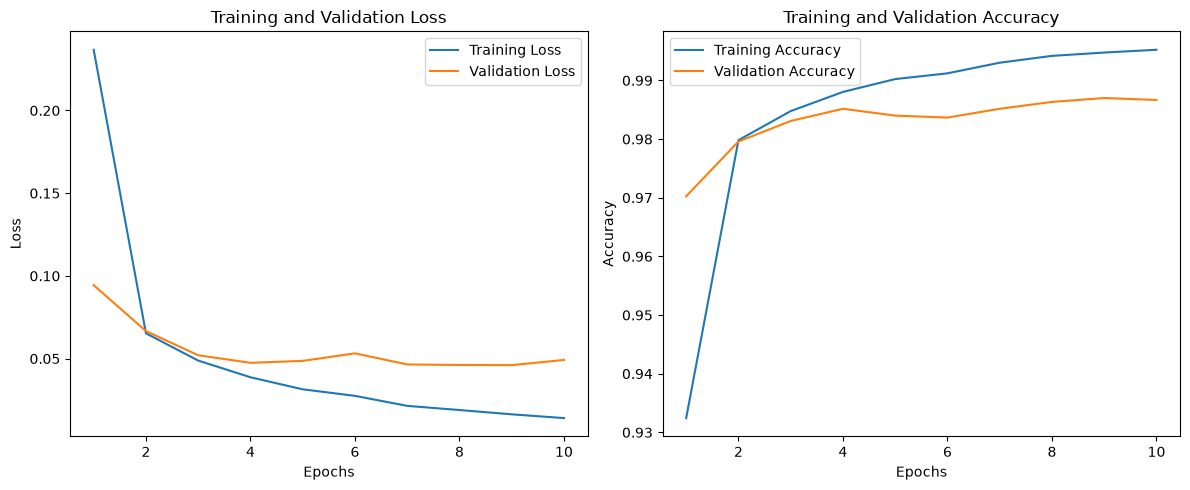

In [28]:
# Generate the plots
plot_metrics(train_loss, train_acc, val_loss, val_acc)

In [29]:
# Evaluate the model on the test dataset
def evaluate_model(model, test_loader):
    model.eval() # Set the model to evaluation mode
    correct = 0
    total = 0
    with torch.no_grad(): # Disable gradient calculation for evaluation to save memory and computations
        for images, labels in test_loader:
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0) # size(0) returns the batch size, which is the number of samples in the current batch.
            correct += (predicted == labels).sum().item()
    accuracy = 100 * correct / total
    print(f'Accuracy of the model on the test images: {accuracy:.2f}%')
    return accuracy

In [30]:
# Initialize the test loader
test_loader = DataLoader(testing_data, batch_size=64, shuffle=False)

In [31]:
# Evaluate the model using  testing data
accuracy = evaluate_model(model, test_loader)

Accuracy of the model on the test images: 98.91%


#### Part 2: CNN for CIFAR10 Dataset

- Load cifar10 dataset. Build a CNN network with convolution layers to classify the images.
- Print the accuracy. 
- Tune the hyper parameters if needed to get a good accuracy.

In [32]:
# Load CIFAR-10 dataset with data augmentation
# Transform only for training and evaluation
transform_1 = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomCrop(32, padding=4),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])

# Transform only for testing to make sure the test accuracies are measured using the same test images
test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])


training_data_1 = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform_1)
testing_data_1 = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=test_transform)

In [33]:
# Inspect the shape of the data and labels for CIFAR-10 to help design the model architecture. 
print(f"Training data shape (CIFAR-10): {training_data_1.data.shape}")
print(f"Training labels shape (CIFAR-10): {len(training_data_1.targets)}")  
print(f"Testing data shape (CIFAR-10): {testing_data_1.data.shape}")
print(f"Testing labels shape (CIFAR-10): {len(testing_data_1.targets)}")  

Training data shape (CIFAR-10): (50000, 32, 32, 3)
Training labels shape (CIFAR-10): 50000
Testing data shape (CIFAR-10): (10000, 32, 32, 3)
Testing labels shape (CIFAR-10): 10000


In [34]:
# Find the number of classes in the CIFAR-10 dataset to determine the number of neurons in the output layer of the model. 
num_classes = len(set(training_data_1.targets))
print(f"Number of classes in CIFAR-10 dataset: {num_classes}")

Number of classes in CIFAR-10 dataset: 10


#### Data Loader Preparation 

- Training Loader
- Validation Loader

In [35]:
# Split the CIFAR-10 training data into training and validation sets
train_size_1 = int(0.8 * len(training_data_1))
val_size_1 = len(training_data_1) - train_size_1
training_data_1, validation_data_1 = utils.data.random_split(training_data_1, [train_size_1, val_size_1])

# Initialize the train loader
train_loader_1 = DataLoader(training_data_1, batch_size=64, shuffle=True)

# Initialize the validation loader
val_loader_1 = DataLoader(validation_data_1, batch_size=64, shuffle=False)

##### (1) Base Model with only convolution and max pooling layers, just as the one used in Part 1 with adjusted dimensions.  

In [36]:
class CNN_CIFAR10(nn.Module):
    def __init__(self, out_1=32, out_2=64, output_linear = num_classes):
        super().__init__()
        self.conv1 = nn.Conv2d(3, out_1, kernel_size=3, stride=1, padding=1)
        self.maxpool1 = nn.MaxPool2d(kernel_size=2)
        self.conv2 = nn.Conv2d(out_1, out_2, kernel_size=3, stride=1, padding=1)
        self.maxpool2 = nn.MaxPool2d(kernel_size=2)
        self.fc1 = nn.Linear(out_2 * 8 * 8, output_linear)

    def forward(self, x):
        x = self.maxpool1(torch.relu(self.conv1(x)))
        x = self.maxpool2(torch.relu(self.conv2(x)))
        x = x.view(x.size(0), -1) # Flatten the tensor for the fully connected layer
        x = self.fc1(x)
        return x

In [37]:
# Initialize the model, loss function, and optimizer for CIFAR-10 for a dry-run training
model_CIFAR10 = CNN_CIFAR10()
loss_CIFAR10 = nn.CrossEntropyLoss()
optimizer_CIFAR10 = optim.Adam(model_CIFAR10.parameters(), lr=0.001)

In [38]:
# Start training the model for CIFAR-10 (dry-run). 
train_loss_1, train_acc_1, val_loss_1, val_acc_1 = train_model(
    model_CIFAR10, train_loader_1, val_loader_1, loss_CIFAR10, optimizer_CIFAR10, num_epochs=100
)

Epoch [1/100], TrainingLoss: 1.5789, TrainingAccuracy: 0.4265, ValidationLoss: 1.3913, ValidationAccuracy: 0.4984
Epoch [2/100], TrainingLoss: 1.2684, TrainingAccuracy: 0.5513, ValidationLoss: 1.2462, ValidationAccuracy: 0.5536
Epoch [3/100], TrainingLoss: 1.1359, TrainingAccuracy: 0.6003, ValidationLoss: 1.1363, ValidationAccuracy: 0.5980
Epoch [4/100], TrainingLoss: 1.0695, TrainingAccuracy: 0.6218, ValidationLoss: 1.0385, ValidationAccuracy: 0.6421
Epoch [5/100], TrainingLoss: 1.0133, TrainingAccuracy: 0.6460, ValidationLoss: 0.9967, ValidationAccuracy: 0.6545
Epoch [6/100], TrainingLoss: 0.9902, TrainingAccuracy: 0.6568, ValidationLoss: 0.9769, ValidationAccuracy: 0.6625
Epoch [7/100], TrainingLoss: 0.9595, TrainingAccuracy: 0.6667, ValidationLoss: 0.9656, ValidationAccuracy: 0.6601
Epoch [8/100], TrainingLoss: 0.9330, TrainingAccuracy: 0.6774, ValidationLoss: 0.9512, ValidationAccuracy: 0.6678
Epoch [9/100], TrainingLoss: 0.9129, TrainingAccuracy: 0.6849, ValidationLoss: 0.9291, V

#### (2) A updated model with more output channels, attempting to capture more complex features.  

In [39]:
# Try a different model with larger number of output channels. 

model_CIFAR10_2 = CNN_CIFAR10(out_1=64, out_2=128)
loss_CIFAR10_2 = nn.CrossEntropyLoss()
optimizer_CIFAR10_2 = optim.Adam(model_CIFAR10_2.parameters(), lr=0.001)

In [40]:
# Start training the model for CIFAR-10 (with a larger number of epochs and lower learning rate). 
train_loss_2, train_acc_2, val_loss_2, val_acc_2 = train_model(
    model_CIFAR10_2, train_loader_1, val_loader_1, loss_CIFAR10_2, optimizer_CIFAR10_2, num_epochs=20
)

Epoch [1/20], TrainingLoss: 1.5457, TrainingAccuracy: 0.4410, ValidationLoss: 1.3486, ValidationAccuracy: 0.5083
Epoch [2/20], TrainingLoss: 1.2191, TrainingAccuracy: 0.5674, ValidationLoss: 1.1787, ValidationAccuracy: 0.5839
Epoch [3/20], TrainingLoss: 1.1007, TrainingAccuracy: 0.6129, ValidationLoss: 1.0925, ValidationAccuracy: 0.6157
Epoch [4/20], TrainingLoss: 1.0277, TrainingAccuracy: 0.6407, ValidationLoss: 1.0045, ValidationAccuracy: 0.6470
Epoch [5/20], TrainingLoss: 0.9839, TrainingAccuracy: 0.6574, ValidationLoss: 0.9741, ValidationAccuracy: 0.6599
Epoch [6/20], TrainingLoss: 0.9483, TrainingAccuracy: 0.6691, ValidationLoss: 0.9571, ValidationAccuracy: 0.6686
Epoch [7/20], TrainingLoss: 0.9192, TrainingAccuracy: 0.6805, ValidationLoss: 0.9100, ValidationAccuracy: 0.6853
Epoch [8/20], TrainingLoss: 0.8913, TrainingAccuracy: 0.6895, ValidationLoss: 0.8809, ValidationAccuracy: 0.6975
Epoch [9/20], TrainingLoss: 0.8715, TrainingAccuracy: 0.6968, ValidationLoss: 0.8730, Validation

##### Do it one more time with num_epochs = 100 as the validation loss kept dropping

In [41]:
model_CIFAR10_2 = CNN_CIFAR10(out_1=64, out_2=128)
loss_CIFAR10_2 = nn.CrossEntropyLoss()
optimizer_CIFAR10_2 = optim.Adam(model_CIFAR10_2.parameters(), lr=0.001)
train_loss_2, train_acc_2, val_loss_2, val_acc_2 = train_model(
    model_CIFAR10_2, train_loader_1, val_loader_1, loss_CIFAR10_2, optimizer_CIFAR10_2, num_epochs=100
    )

Epoch [1/100], TrainingLoss: 1.5382, TrainingAccuracy: 0.4438, ValidationLoss: 1.3144, ValidationAccuracy: 0.5355
Epoch [2/100], TrainingLoss: 1.2118, TrainingAccuracy: 0.5706, ValidationLoss: 1.1416, ValidationAccuracy: 0.5984
Epoch [3/100], TrainingLoss: 1.0906, TrainingAccuracy: 0.6179, ValidationLoss: 1.1146, ValidationAccuracy: 0.6046
Epoch [4/100], TrainingLoss: 1.0132, TrainingAccuracy: 0.6489, ValidationLoss: 1.0151, ValidationAccuracy: 0.6367
Epoch [5/100], TrainingLoss: 0.9632, TrainingAccuracy: 0.6651, ValidationLoss: 0.9481, ValidationAccuracy: 0.6675
Epoch [6/100], TrainingLoss: 0.9234, TrainingAccuracy: 0.6803, ValidationLoss: 0.9086, ValidationAccuracy: 0.6832
Epoch [7/100], TrainingLoss: 0.8902, TrainingAccuracy: 0.6901, ValidationLoss: 0.9054, ValidationAccuracy: 0.6830
Epoch [8/100], TrainingLoss: 0.8607, TrainingAccuracy: 0.7013, ValidationLoss: 0.8847, ValidationAccuracy: 0.6922
Epoch [9/100], TrainingLoss: 0.8408, TrainingAccuracy: 0.7053, ValidationLoss: 0.8937, V

#### (3) The same model but a smaller starting learning rate with a learning rate scheduler

In [42]:
# Initialize a new model, loss function, and optimizer for CIFAR-10 looking for better training performance.
# Keep the architecture of the model the same, but with a smaller starting learning rate and adjust the learning rate by a scheduler during training based on the validation loss.
model_CIFAR10_3 = CNN_CIFAR10(out_1=64, out_2=128)
loss_CIFAR10_3 = nn.CrossEntropyLoss()
optimizer_CIFAR10_3 = optim.Adam(model_CIFAR10_3.parameters(), lr=0.001)


In [43]:
# Initialize a scheduler for learning rate adjustment during training.

scheduler_CIFAR10_3 = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_CIFAR10_3,
    mode='min', # mode='min' means that the learning rate will be reduced when the quantity monitored has stopped decreasing. In this case, we are monitoring the validation loss, so if the validation loss does not decrease for a certain number of epochs (patience), the learning rate will be reduced.
    factor=0.5, # The factor by which the learning rate will be reduced. new_lr = lr * factor
    patience=5 # The number of epochs to wait for improvement before reducing the learning rate
)

In [44]:
# Start training the model for CIFAR-10 with the learning rate scheduler.
train_loss_3, train_acc_3, val_loss_3, val_acc_3 = train_model(
    model_CIFAR10_3, train_loader_1, val_loader_1, loss_CIFAR10_3, optimizer_CIFAR10_3, num_epochs=100, scheduler=scheduler_CIFAR10_3
)

Epoch [1/100], TrainingLoss: 1.5308, TrainingAccuracy: 0.4491, ValidationLoss: 1.3175, ValidationAccuracy: 0.5258
Epoch [2/100], TrainingLoss: 1.2255, TrainingAccuracy: 0.5652, ValidationLoss: 1.1421, ValidationAccuracy: 0.5998
Epoch [3/100], TrainingLoss: 1.1029, TrainingAccuracy: 0.6120, ValidationLoss: 1.1047, ValidationAccuracy: 0.6065
Epoch [4/100], TrainingLoss: 1.0274, TrainingAccuracy: 0.6429, ValidationLoss: 1.0050, ValidationAccuracy: 0.6502
Epoch [5/100], TrainingLoss: 0.9773, TrainingAccuracy: 0.6579, ValidationLoss: 1.0003, ValidationAccuracy: 0.6544
Epoch [6/100], TrainingLoss: 0.9350, TrainingAccuracy: 0.6731, ValidationLoss: 0.9561, ValidationAccuracy: 0.6606
Epoch [7/100], TrainingLoss: 0.8985, TrainingAccuracy: 0.6861, ValidationLoss: 0.8927, ValidationAccuracy: 0.6942
Epoch [8/100], TrainingLoss: 0.8694, TrainingAccuracy: 0.6985, ValidationLoss: 0.8911, ValidationAccuracy: 0.6847
Epoch [9/100], TrainingLoss: 0.8502, TrainingAccuracy: 0.7083, ValidationLoss: 0.8626, V

#### (4) An updated model with two normalization layers
- Make the training more stable by keeping the intermediate feature values at a more consistent scale.

In [45]:
# Adjust the model architecture to include a normalization layer.
# A normalization layer is often added to neural networks to improve training stability and convergence. 
# Create the CNN model using pytorch
class CNN_Norm(nn.Module):
    def __init__(self, out_1=16, out_2=32):
        super().__init__()
        self.conv1 = nn.Conv2d(3, out_1, kernel_size=3, stride=1, padding=1)
        self.bn1 = nn.BatchNorm2d(out_1)
        self.maxpool1 = nn.MaxPool2d(kernel_size=2)
        self.conv2 = nn.Conv2d(out_1, out_2, kernel_size=3, stride=1, padding=1)
        self.bn2 = nn.BatchNorm2d(out_2)
        self.maxpool2 = nn.MaxPool2d(kernel_size=2)
        self.fc1 = nn.Linear(out_2 * 8 * 8, 10)

    def forward(self, x):
        x = self.maxpool1(torch.relu(self.bn1(self.conv1(x))))
        x = self.maxpool2(torch.relu(self.bn2(self.conv2(x))))
        x = x.view(x.size(0), -1)  # Flatten the tensor for the fully connected layer
        x = self.fc1(x)
        return x 

In [46]:
# Initialize the model, loss function, and optimizer for CIFAR-10
model_CIFAR10_4 = CNN_Norm(out_1=64, out_2=128)
loss_CIFAR10_4 = nn.CrossEntropyLoss()
optimizer_CIFAR10_4 = optim.Adam(model_CIFAR10_4.parameters(), lr=0.001)
scheduler_CIFAR10_4 = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_CIFAR10_4,
    mode = 'min',
    factor = 0.5,
    patience= 5
)

In [47]:
# Start training the model for CIFAR-10 with the learning rate scheduler and normalization layer.
train_loss_4, train_acc_4, val_loss_4, val_acc_4 = train_model(
    model_CIFAR10_4, train_loader_1, val_loader_1, loss_CIFAR10_4, optimizer_CIFAR10_4, num_epochs=100, scheduler=scheduler_CIFAR10_4
)

Epoch [1/100], TrainingLoss: 1.6543, TrainingAccuracy: 0.4370, ValidationLoss: 1.2847, ValidationAccuracy: 0.5473
Epoch [2/100], TrainingLoss: 1.2255, TrainingAccuracy: 0.5697, ValidationLoss: 1.2003, ValidationAccuracy: 0.5854
Epoch [3/100], TrainingLoss: 1.1038, TrainingAccuracy: 0.6146, ValidationLoss: 1.0435, ValidationAccuracy: 0.6329
Epoch [4/100], TrainingLoss: 1.0291, TrainingAccuracy: 0.6409, ValidationLoss: 1.0620, ValidationAccuracy: 0.6287
Epoch [5/100], TrainingLoss: 0.9694, TrainingAccuracy: 0.6645, ValidationLoss: 1.0736, ValidationAccuracy: 0.6267
Epoch [6/100], TrainingLoss: 0.9258, TrainingAccuracy: 0.6796, ValidationLoss: 1.0127, ValidationAccuracy: 0.6440
Epoch [7/100], TrainingLoss: 0.8959, TrainingAccuracy: 0.6909, ValidationLoss: 0.9039, ValidationAccuracy: 0.6864
Epoch [8/100], TrainingLoss: 0.8650, TrainingAccuracy: 0.7005, ValidationLoss: 0.8933, ValidationAccuracy: 0.6905
Epoch [9/100], TrainingLoss: 0.8356, TrainingAccuracy: 0.7143, ValidationLoss: 0.8922, V

In [48]:
# Initialize the test loader for CIFAR-10
test_loader_1 = DataLoader(testing_data_1, batch_size=64, shuffle=False)

In [49]:
# Evaluate all the models on the test dataset for CIFAR-10
print("Evaluating base model on test dataset:")
accuracy_1 = evaluate_model(model_CIFAR10, test_loader_1)
print("Evaluating model_CIFAR10_2 on test dataset:")
accuracy_2 = evaluate_model(model_CIFAR10_2, test_loader_1)
print("Evaluating model_CIFAR10_3 on test dataset:")
accuracy_3 = evaluate_model(model_CIFAR10_3, test_loader_1)
print("Evaluating model_CIFAR10_4 on test dataset:")
accuracy_4 = evaluate_model(model_CIFAR10_4, test_loader_1)

Evaluating base model on test dataset:
Accuracy of the model on the test images: 78.84%
Evaluating model_CIFAR10_2 on test dataset:
Accuracy of the model on the test images: 79.83%
Evaluating model_CIFAR10_3 on test dataset:
Accuracy of the model on the test images: 81.62%
Evaluating model_CIFAR10_4 on test dataset:
Accuracy of the model on the test images: 84.18%


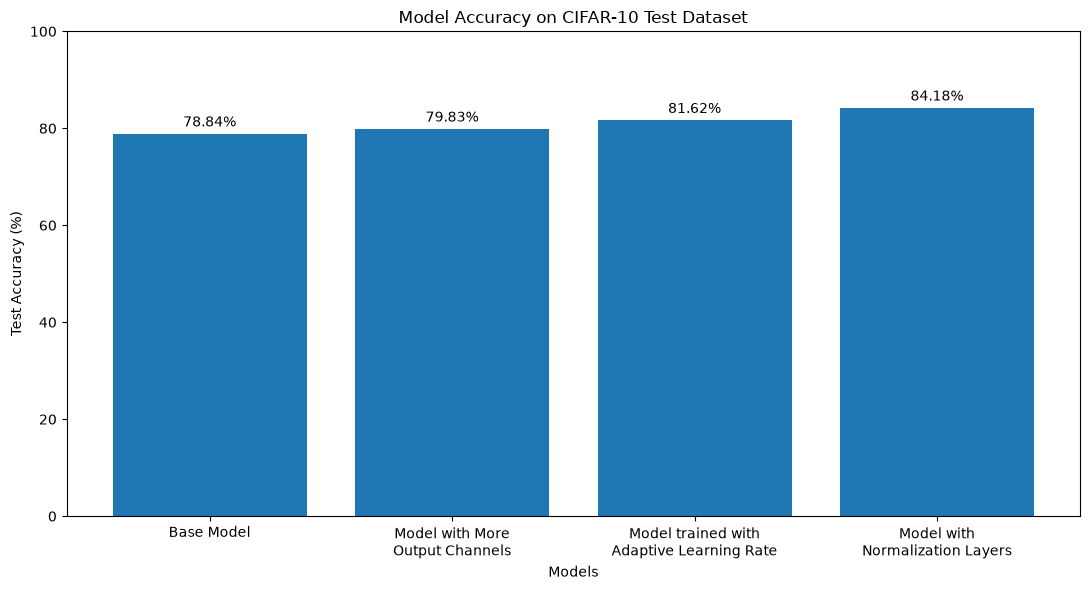

In [50]:
# Compare CIFAR-10 test accuracy with readable model labels.
models = [
    'Base Model',
    'Model with More\nOutput Channels',
    'Model trained with\nAdaptive Learning Rate',
    'Model with\nNormalization Layers',
]
accuracies = [accuracy_1, accuracy_2, accuracy_3, accuracy_4]

plt.figure(figsize=(11, 6))
bars = plt.bar(models, accuracies)
plt.title('Model Accuracy on CIFAR-10 Test Dataset')
plt.xlabel('Models')
plt.ylabel('Test Accuracy (%)')
plt.ylim(0, 100)
plt.bar_label(bars, fmt='%.2f%%', padding=3)
plt.tight_layout()
plt.show()


*A brief discussion and summary about the results:*

For CIFAR-10, I have explored 4 different models with the time constraint for this assignment. The base CNN achieved a test accuracy of 78.84%. Increasing the number of output channels from 64 to 128 improved accuracy to 79.83%, while adding an adaptive learning rate scheduler to the wider model increased it to 81.62%. The model combining wider channels, the scheduler, and batch normalization achieved the highest accuracy of 84.18%, an overall improvement of 5.34 percentage points over the base model. All four models were trained for 100 epochs and evaluated on the same test dataset. These results suggest that additional model capacity provided a modest benefit, while learning rate scheduling and batch normalization produced further improvements in this experiment. Overall, the final model was the most effective configuration tested for CIFAR-10 classification.
